# Processed TSG baseline: compare whole holes

**One row = one hole**, summarised by the frequency of its valid primary mineral-group labels. This does not cluster individual spectra or depths and does not predict gold.

First run `hylogger prepare --selection tsg_pilot --source processed`. No raw ZIPs are needed. Use the **HyLogger Data Crunch (Python 3.11)** kernel, then run cells from top to bottom.

The five-hole cohort is a small workflow test, not a representative geological study. See `docs/TSG_BASELINE_FIRST_TEST.md` for the full download and preparation steps.

In [28]:
import matplotlib.pyplot as plt
from IPython.display import display

from hylogger.baseline import fit_baseline, load_baseline_inputs, save_baseline_run
from hylogger.config import AppConfig

In [29]:
# Change these settings here before running the remaining cells.
SELECTION = "tsg_regional_20"       # Named cohort from configs/selections/.
FEATURE_LOG = "grp1_u_tsas"   # One shared user-level SWIR group log, not all numeric columns.
N_CLUSTERS = 5               # First test: 2 clusters across 5 holes; must be less than hole count.
RANDOM_STATE = 42            # Reproducible K-Means initialisation.
PCA_VARIANCE = None          # None: no PCA; set 0.95 to apply PCA before K-Means.

config = AppConfig.load()    # Finds the installed project, even when launched elsewhere.

## 1. Check which readings contribute

Missing labels and invalid/aspectral/not-a-rock labels are excluded. Their rates are shown below, not used as clustering features. A missing or entirely invalid log stops the run; it is not silently filled with zeros.

A low valid percentage is a warning: the profile describes only the available valid labels. These counts are not a full mask/error-based quality assessment.

In [30]:
inputs = load_baseline_inputs(config, SELECTION, feature_log=FEATURE_LOG)
print(f"Loaded {len(inputs.proportions)} holes from processed logs only.")
display(inputs.quality.round(2))
low_coverage = inputs.quality.index[inputs.quality["valid_pct"] < 50].tolist()
if low_coverage:
    print(f"Review these holes: fewer than half their rows have valid labels: {low_coverage}")
    print("This is a warning for review, not an automatic exclusion threshold.")

Loaded 20 holes from processed logs only.


,total_rows,valid_rows,missing_rows,invalid_rows,valid_pct,missing_pct,invalid_pct
hole_id,,,,,,,
MND032,14250,7709,3145,3396,54.10,22.07,23.83
MND037,27270,19416,4201,3653,71.20,15.41,13.40
MND040,22930,18743,3815,372,81.74,16.64,1.62
MPWD10,21564,15514,4849,1201,71.94,22.49,5.57
MPWD11,47970,31723,9672,6575,66.13,20.16,13.71
MPWD12,34440,26946,6817,677,78.24,19.79,1.97
MPWD3,13167,8246,3905,1016,62.63,29.66,7.72
MPWD6,11315,7317,3606,392,64.67,31.87,3.46
MPWD7,27664,19223,6747,1694,69.49,24.39,6.12


Review these holes: fewer than half their rows have valid labels: ['YRC08-17D', 'YRC09-01D']
This is a warning for review, not an automatic exclusion threshold.


## 2. See the actual model inputs

Each row below sums to 100%. For example, 40% chlorite means that 40% of the **valid primary group labels** in that hole are chlorite. It does not mean 40% chlorite by rock mass or volume. These are reading-count proportions, not depth-weighted proportions.

Each hole has equal weight in the model regardless of its number of readings. Depth order is lost in this whole-hole summary.

,amphibole,carbonate,chlorite,dark_mica,epidote,kaolin,other_aloh,other_mgoh,serpentine,smectite,sulphate,tourmaline,white_mica
hole_id,,,,,,,,,,,,,
MND032,11.70,0.88,72.67,1.36,1.47,0.18,1.25,1.45,0.04,0.16,0.19,0.13,8.52
MND037,53.96,0.59,32.09,2.47,0.72,0.41,0.42,0.01,0.02,1.94,0.48,0.10,6.81
MND040,40.56,0.20,49.15,0.50,0.62,0.09,2.50,0.02,0.04,0.41,0.06,0.05,5.80
MPWD10,8.65,2.91,66.08,4.08,0.46,12.52,0.08,0.08,0.01,0.00,5.03,0.02,0.08
MPWD11,0.38,0.78,82.87,1.60,0.23,11.56,0.13,0.03,0.01,0.36,1.77,0.03,0.25
MPWD12,3.51,3.99,85.55,1.68,0.49,0.01,0.00,2.31,0.01,0.01,1.93,0.05,0.46
MPWD3,0.13,3.58,75.83,2.44,0.19,3.81,0.06,2.29,0.01,1.24,10.15,0.01,0.25
MPWD6,0.26,9.70,67.15,8.00,1.69,1.54,0.14,0.00,0.03,2.01,8.45,0.05,0.98
MPWD7,3.66,7.70,65.88,6.47,0.58,4.93,0.08,0.51,0.01,0.51,9.09,0.11,0.46


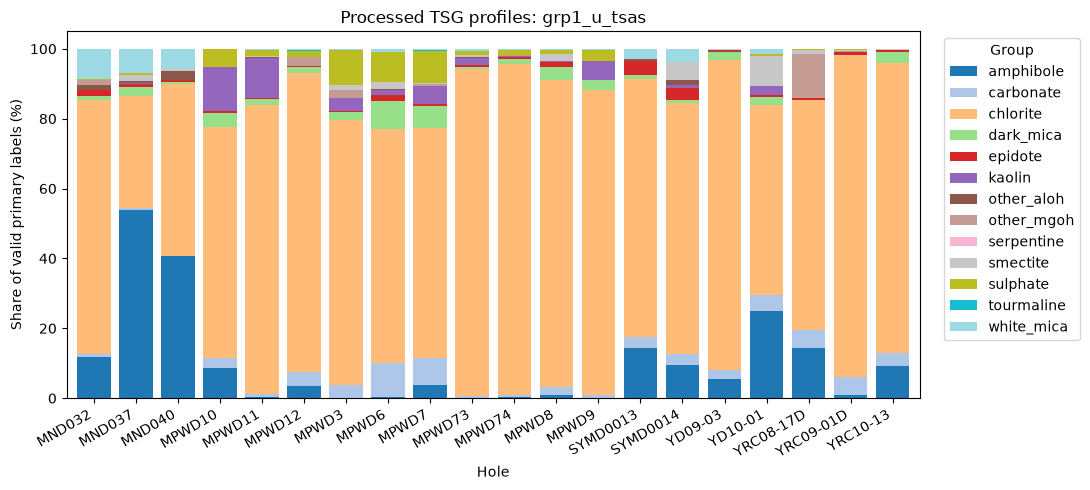

In [31]:
display((inputs.proportions * 100).round(2))
ax = (inputs.proportions * 100).plot.bar(
    stacked=True, figsize=(11, 5), width=0.8, colormap="tab20"
)
ax.set_ylabel("Share of valid primary labels (%)")
ax.set_xlabel("Hole")
ax.set_title(f"Processed TSG profiles: {FEATURE_LOG}")
ax.legend(title="Group", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 3. Fit the baseline

Pipeline: remove constant columns -> standardise proportions -> optional PCA -> K-Means.

PCA is a dimension-reduction step, not the clustering algorithm. With `PCA_VARIANCE = None`, this run uses **no PCA**. Standardising gives each varying group comparable influence; rare groups can therefore matter more than their raw percentages suggest.

Only the chosen log's group proportions enter the model. Hole IDs, depth, missing rates, other spectral regions and processing levels are not features.

In [32]:
result = fit_baseline(
    inputs,
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    pca_variance=PCA_VARIANCE,
)
display(result.assignments.sort_values(["cluster_id", "hole_id"]))
print(f"Silhouette score: {result.metrics['silhouette_score']:.3f}")
print(f"PCA components: {result.metrics['pca_components']} (None means PCA was not used)")
print(f"Cluster sizes: {result.metrics['cluster_sizes']}")
if result.metrics["has_singleton_cluster"]:
    print("Caution: at least one cluster contains only one hole.")
print("Five holes are only a workflow test. This score does not validate geological meaning.")

,hole_id,cluster_id
7,MPWD6,0
8,MPWD7,0
3,MPWD10,1
4,MPWD11,1
5,MPWD12,1
6,MPWD3,1
9,MPWD73,1
10,MPWD74,1
11,MPWD8,1
12,MPWD9,1


Silhouette score: 0.299
PCA components: None (None means PCA was not used)
Cluster sizes: {'0': 2, '1': 11, '2': 3, '3': 3, '4': 1}
Caution: at least one cluster contains only one hole.
Five holes are only a workflow test. This score does not validate geological meaning.


## 4. Save the run

Saves assignments, the input proportions, quality counts, feature names, parameters, input checksum and library versions in a new timestamped folder. No downloads or earlier runs are overwritten.

In [33]:
run_dir = save_baseline_run(config, inputs, result, selection=SELECTION)
print(f"Saved run: {run_dir}")

Saved run: C:\Users\DCCN9\OneDrive - UWA\Data Science\4-Semester July-November 2026\Capstone\Data Crunch\experiments\tsg_baseline\20260827T045016_290686Z


## What to ask next

- Which holes received the same cluster ID, and do their group profiles look similar?
- Are different missing/invalid rates affecting how representative each profile is?
- Does a cluster mostly reflect location, acquisition or processing differences?

Cluster numbers are arbitrary labels, not rankings. TSG interpretations are not ground truth. We have not checked every scan generation or processing history for this convenience cohort. Keep this result separate from the raw-spectral workflow in `03_improved_cluster.ipynb`.